In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import RFE
from sklearn.model_selection import GridSearchCV
!pip install shap -q
import shap













In [2]:
# Φόρτωση δεδομένων
aids_dataset = fetch_ucirepo(id=890)
df = aids_dataset.data.original
df

,pidnum,cid,time,trt,age,wtkg,hemo,homo,drugs,karnof,...,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820
0,10056,0,948,2,48,89.8128,0,0,0,100,...,0,0,1,0,1,0,422,477,566,324
1,10059,1,1002,3,61,49.4424,0,0,0,90,...,0,1,3,0,1,0,162,218,392,564
2,10089,0,961,3,45,88.4520,0,1,1,90,...,1,1,3,0,1,1,326,274,2063,1893
3,10093,0,1166,3,47,85.2768,0,1,0,100,...,1,1,3,0,1,0,287,394,1590,966
4,10124,0,1090,0,43,66.6792,0,1,0,100,...,1,1,3,0,0,0,504,353,870,782
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2134,990021,0,1091,3,21,53.2980,1,0,0,100,...,1,1,3,0,1,1,152,109,561,720
2135,990026,0,395,0,17,102.9672,1,0,0,100,...,1,1,3,0,0,1,373,218,1759,1030
2136,990030,0,1104,2,53,69.8544,1,1,0,90,...,1,1,3,0,1,0,419,364,1391,1041
2137,990071,1,465,0,14,60.0000,1,0,0,100,...,1,0,1,0,0,0,166,169,999,1838


In [3]:
# Αφαίρεση μεταβλητών που αφορούν το μέλλον και id ασθενών(pidnum)
columns_to_drop = ['pidnum', 'time', 'cid', 'days', 'offtrt','cd820']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# Ορισμός στόχου
target = 'cd420'

In [4]:
# 1.3 Έλεγχος για missing values
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("-> No missing values\n")

-> No missing values



In [5]:
# 1.4 Έλεγχος για διπλότυπα
duplicates = df.duplicated().sum()
print(f"Βρέθηκαν {duplicates} διπλότυπες εγγραφές.\n")

Βρέθηκαν 0 διπλότυπες εγγραφές.



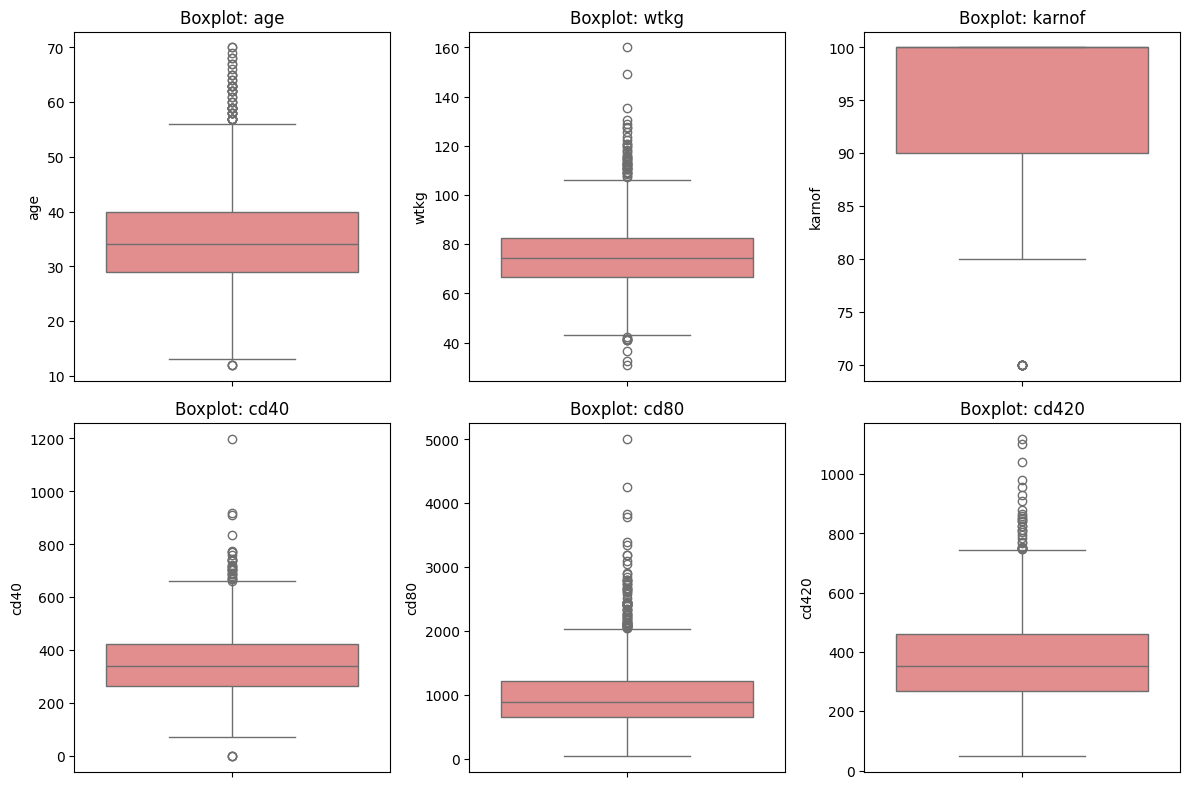

In [6]:
# 1.4 Έλεγχος για outliers
# Επιλέγουμε τις συνεχείς μεταβλητές για έλεγχο ακραίων τιμών
continuous_vars = ['age', 'wtkg', 'karnof', 'cd40', 'cd80', target]

plt.figure(figsize=(12, 8))
for i, col in enumerate(continuous_vars, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='lightcoral')
    plt.title(f'Boxplot: {col}')
plt.tight_layout()
plt.show()

In [7]:
#1.5 περιγραφική στατιστική
desc_stats = round(df.describe().T, 2)
display(desc_stats)

,count,mean,std,min,25%,50%,75%,max
trt,2139.0,1.52,1.13,0.0,1.00,2.00,3.00,3.00
age,2139.0,35.25,8.71,12.0,29.00,34.00,40.00,70.00
wtkg,2139.0,75.13,13.26,31.0,66.68,74.39,82.56,159.94
hemo,2139.0,0.08,0.28,0.0,0.00,0.00,0.00,1.00
homo,2139.0,0.66,0.47,0.0,0.00,1.00,1.00,1.00
drugs,2139.0,0.13,0.34,0.0,0.00,0.00,0.00,1.00
karnof,2139.0,95.45,5.90,70.0,90.00,100.00,100.00,100.00
oprior,2139.0,0.02,0.15,0.0,0.00,0.00,0.00,1.00
z30,2139.0,0.55,0.50,0.0,0.00,1.00,1.00,1.00
zprior,2139.0,1.00,0.00,1.0,1.00,1.00,1.00,1.00


In [8]:
#zprior (1 παντου, καμια προσφορα στο μοντελο)
columns_to_drop = ['zprior']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

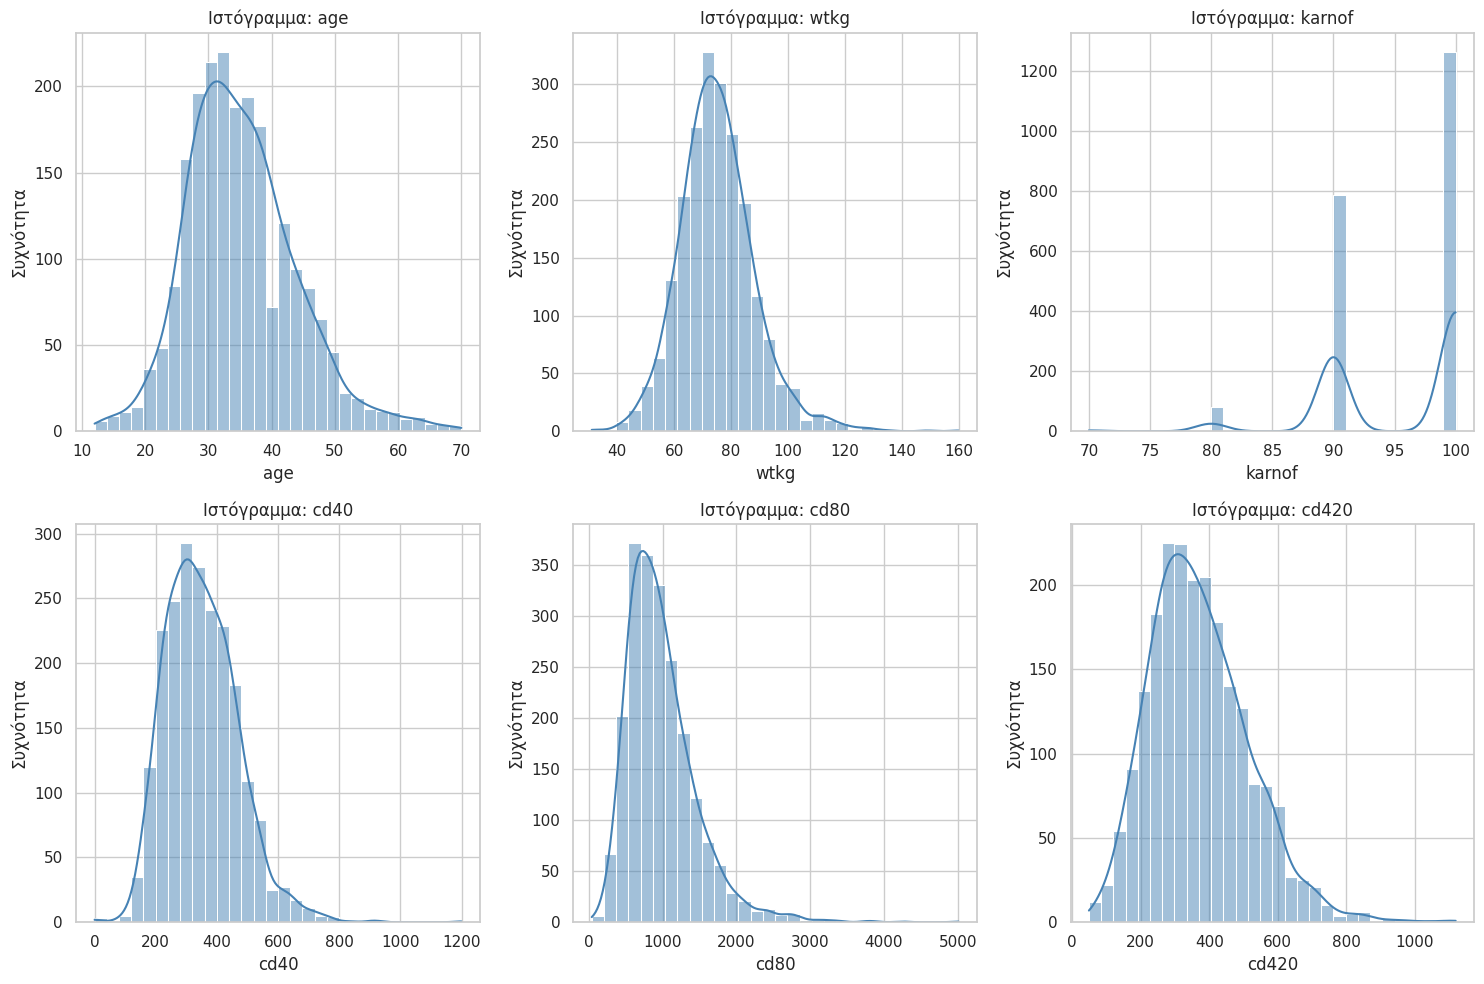

In [9]:
# 1.6 Οπτικοποιήσεις Δεδομένων

sns.set_theme(style="whitegrid", palette="muted")
continuous_vars = ['age', 'wtkg', 'karnof', 'cd40', 'cd80', target]

# Ιστογράμματα
plt.figure(figsize=(15, 10))
for i, col in enumerate(continuous_vars, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, bins=30, color='steelblue')
    plt.title(f'Ιστόγραμμα: {col}')
    plt.xlabel(col)
    plt.ylabel('Συχνότητα')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1500/1552841009.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='trt', y=target, data=df, palette='Set1')


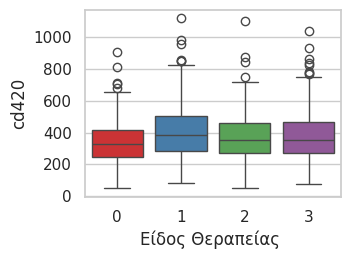

In [10]:
# συνδυαστικό boxplot: Θεραπεία (trt) vs Target (cd420)
plt.subplot(2, 2, 4)
sns.boxplot(x='trt', y=target, data=df, palette='Set1')
plt.xlabel('Είδος Θεραπείας ')
plt.ylabel(target)
plt.tight_layout()
plt.show()

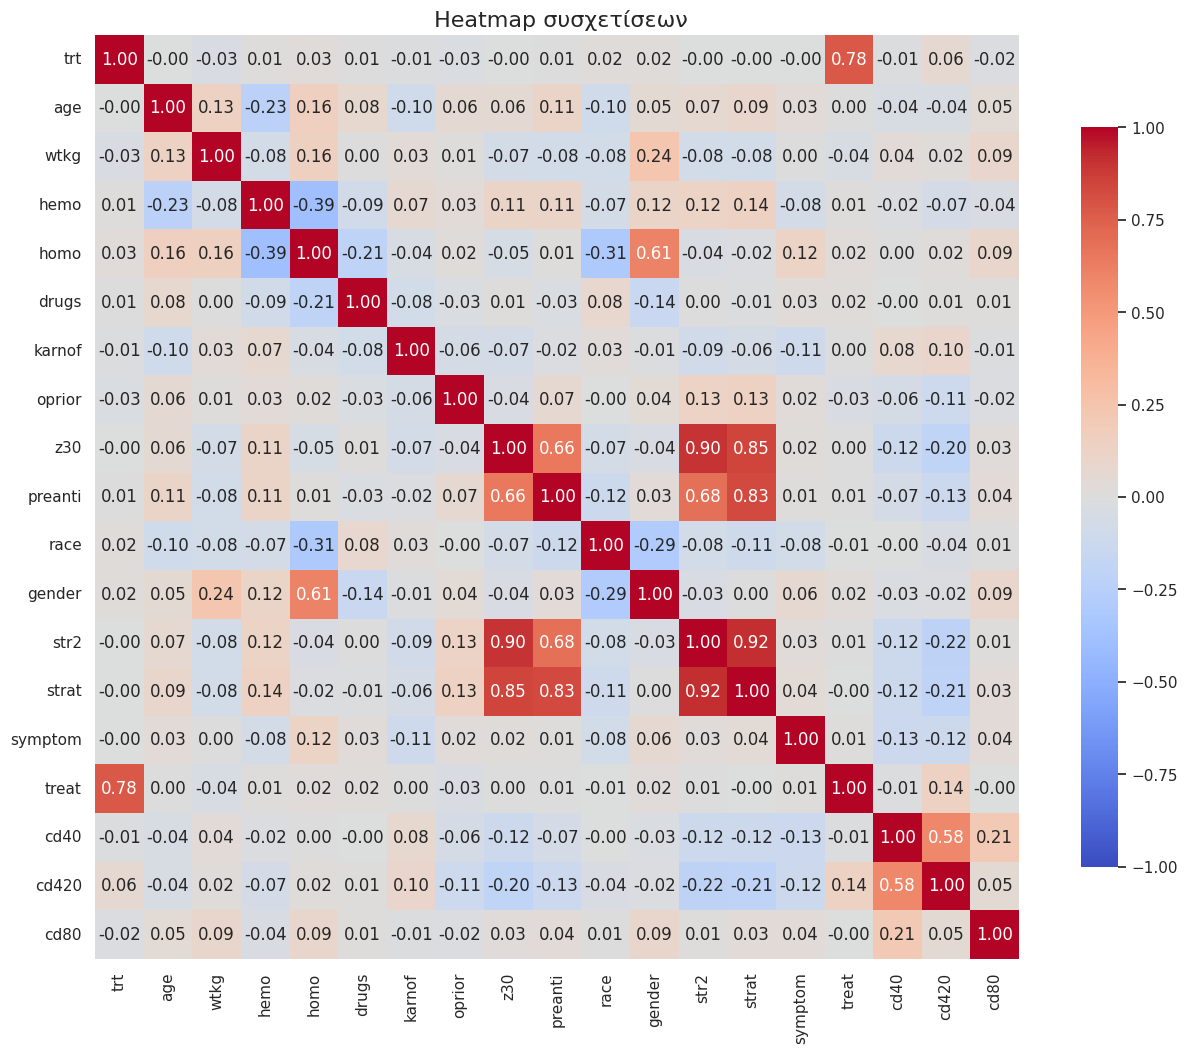

In [11]:
#Heatmap
plt.figure(figsize=(16, 12))
corr_matrix = df.corr()


sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm',
            cbar_kws={"shrink": .8}, square=True, vmin=-1, vmax=1)
plt.title(' Heatmap συσχετίσεων', fontsize=16)
plt.show()

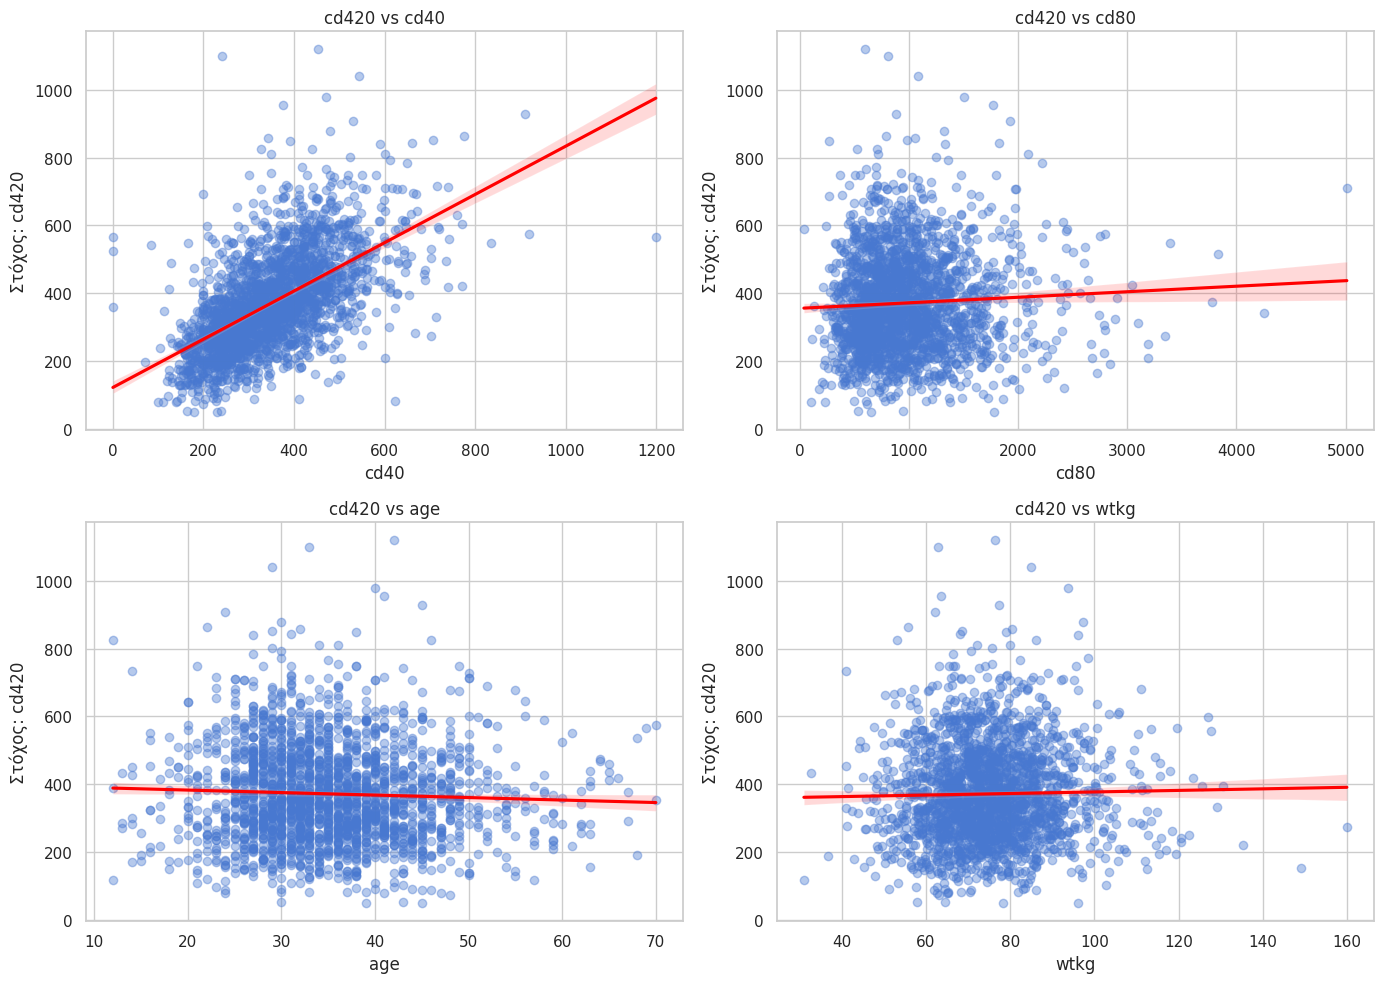

In [12]:
# Scatter Plots
features_to_plot = ['cd40', 'cd80', 'age', 'wtkg']

plt.figure(figsize=(14, 10))
for i, feature in enumerate(features_to_plot, 1):
    plt.subplot(2, 2, i)
    # Χρησιμοποιούμε regplot για να φαίνεται η γραμμή τάσης
    sns.regplot(data=df, x=feature, y=target, scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
    plt.title(f'{target} vs {feature}')
    plt.xlabel(feature)
    plt.ylabel(f'Στόχος: {target}')
plt.tight_layout()
plt.show()

In [13]:
#Train/Test Split
X = df.drop(columns=[target])
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=30)
print(f"Συνολικό πλήθος παρατηρήσεων στο dataset: {len(df)}")
print(f"Πλήθος παρατηρήσεων στο training set: {len(X_train)} (80%)")
print(f"Πλήθος παρατηρήσεων στο test set: {len(X_test)} (20%)")

Συνολικό πλήθος παρατηρήσεων στο dataset: 2139
Πλήθος παρατηρήσεων στο training set: 1711 (80%)
Πλήθος παρατηρήσεων στο test set: 428 (20%)


In [14]:
# 2.2  Τυποποίηση

#  συνεχείς μεταβλητές που χρειάζονται τυποποίηση
continuous_features = ['age', 'wtkg', 'karnof', 'cd40', 'cd80','preanti']
scaler_preprocessor = ColumnTransformer(
    transformers=[
        ('num_scaler', StandardScaler(), continuous_features)
    ],
    remainder='passthrough'
)

In [15]:
# 2.2 & 2.3

# 1. Συνεχείς μεταβλητές (χρειάζονται Standardization)
continuous_features = ['age', 'wtkg', 'karnof', 'cd40', 'cd80', 'preanti']

categorical_features = ['trt']

# 3. Δυαδικές μεταβλητές (τις βρίσκουμε αφαιρώντας τις παραπάνω από το X)
# (Υποθέτουμε ότι το X είναι το dataframe με τα χαρακτηριστικά εισόδου, χωρίς τον στόχο)
binary_features = [col for col in X.columns if col not in continuous_features and col not in categorical_features]

# Δημιουργούμε το ColumnTransformer που κάνει όλες τις δουλειές ταυτόχρονα!
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), continuous_features),
        # drop='first' για να αποφύγουμε την πολυσυγγραμμικότητα
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features),
        # Οι δυαδικές περνάνε ανέπαφες
        ('bin', 'passthrough', binary_features)
    ])

print(f"Συνεχείς μεταβλητές (StandardScaler): {continuous_features}")
print(f"Κατηγορικές μεταβλητές (OneHotEncoder): {categorical_features}")
print(f"Δυαδικές μεταβλητές (Passthrough): {binary_features}")

Συνεχείς μεταβλητές (StandardScaler): ['age', 'wtkg', 'karnof', 'cd40', 'cd80', 'preanti']
Κατηγορικές μεταβλητές (OneHotEncoder): ['trt']
Δυαδικές μεταβλητές (Passthrough): ['hemo', 'homo', 'drugs', 'oprior', 'z30', 'race', 'gender', 'str2', 'strat', 'symptom', 'treat']


In [16]:
# 2.4 Εφαρμογή Προεπεξεργασίας

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [17]:
# 3 Εκπαίδευση και αξιολόγηση baseline μοντέλων

# 1. Αρχικοποίηση των 5 μοντέλων (με default )
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=30),
    "Gradient Boosting": GradientBoostingRegressor(random_state=30),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor()
}


results = {}

for name, model in models.items():
    # Εκπαίδευση
    model.fit(X_train_processed, y_train)

    # Πρόβλεψη
    y_pred = model.predict(X_test_processed)

    # Υπολογισμός Μετρικών
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)


    results[name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

results_df = pd.DataFrame(results).T
display(results_df.sort_values(by='MAE'))

,MAE,MSE,RMSE,R2
Linear Regression,83.196939,12110.651362,110.048405,0.431355
Gradient Boosting,85.833032,12722.965987,112.796126,0.402604
Random Forest,87.243832,13175.824914,114.785996,0.381341
KNN,98.890654,16531.274766,128.574005,0.223789
SVR,100.674727,17140.069217,130.920087,0.195203


In [18]:
#4.1 & 4.2 5-Fold Cross-Validation PIPELINE

kf = KFold(n_splits=5, shuffle=True, random_state=30)
scoring = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error'}
cv_results_list = []

for name, model in models.items():
    # Συνδέει τον preprocessor (από το Κεφ. 2) με το εκάστοτε μοντέλο.
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # αρχικό X_train όχι  processed

    cv_scores = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring)

    mean_r2 = np.mean(cv_scores['test_R2'])
    std_r2 = np.std(cv_scores['test_R2'])
    mean_mae = -np.mean(cv_scores['test_MAE'])
    std_mae = np.std(cv_scores['test_MAE'])

    cv_results_list.append({
        'Μοντέλο': name,
        'Mean R2': mean_r2,
        'Std R2': std_r2,
        'Mean MAE': mean_mae,
        'Std MAE': std_mae
    })

cv_df = pd.DataFrame(cv_results_list)
display(cv_df.sort_values(by='Mean MAE').reset_index(drop=True))

,Μοντέλο,Mean R2,Std R2,Mean MAE,Std MAE
0,Linear Regression,0.377938,0.060524,84.708143,2.908052
1,Gradient Boosting,0.376019,0.046089,85.251464,3.401322
2,Random Forest,0.346601,0.058782,87.706301,2.715168
3,KNN,0.214526,0.053557,98.045804,2.683835
4,SVR,0.173223,0.013926,100.059950,2.638331


In [19]:
#5.1 Μεθόδοι φίλτρου (Mutual Information & Correlation)
X_train_processed = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()

mi_scores = mutual_info_regression(X_train_processed, y_train,random_state=30)

temp_df = pd.DataFrame(X_train_processed, columns=feature_names)
temp_df['TARGET_cd420'] = y_train.values
#παίρνουμε την απόλυτη τιμή μας νοιάζει το μέγεθος, όχι το πρόσημο
corr_scores = temp_df.corr()['TARGET_cd420'].abs().drop('TARGET_cd420').values

feature_scores_df = pd.DataFrame({
    'Χαρακτηριστικό': feature_names,
    'Mutual_Information': mi_scores,
    'Absolute_Correlation': corr_scores
})
feature_scores_df = feature_scores_df.sort_values(by='Mutual_Information', ascending=False).reset_index(drop=True)
display(feature_scores_df)



,Χαρακτηριστικό,Mutual_Information,Absolute_Correlation
0,num__cd40,0.240356,0.576118
1,bin__str2,0.056001,0.231808
2,bin__z30,0.040721,0.219551
3,num__preanti,0.039679,0.151466
4,bin__strat,0.029665,0.219880
5,num__karnof,0.016400,0.096855
6,cat__trt_3,0.013993,0.012410
7,bin__oprior,0.013974,0.093775
8,cat__trt_1,0.013109,0.124680
9,bin__treat,0.011330,0.135813


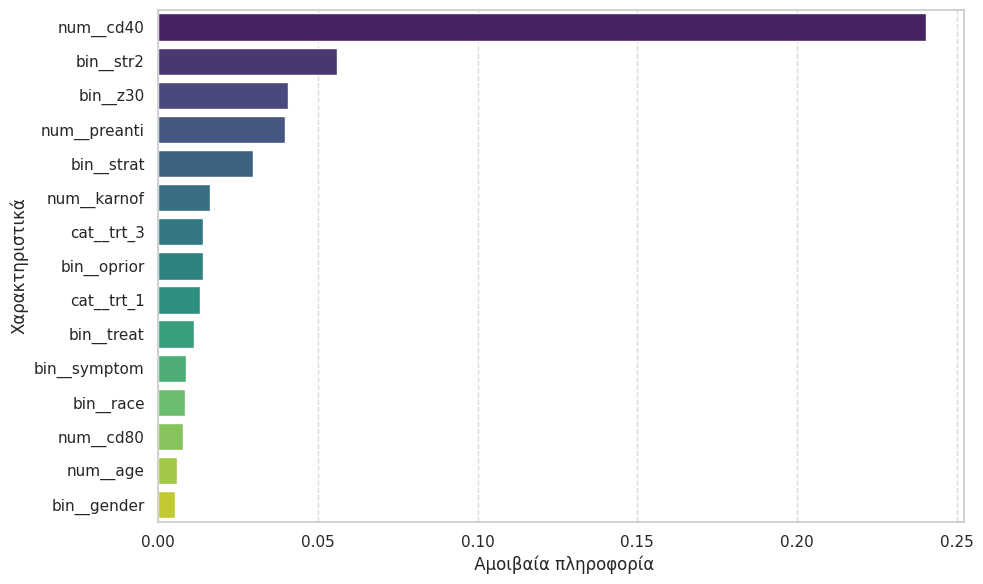

In [20]:
# 5 Mutual Information
plt.figure(figsize=(10, 6))
sns.barplot(x='Mutual_Information', y='Χαρακτηριστικό', data=feature_scores_df.head(15), hue='Χαρακτηριστικό', palette='viridis', legend=False)
plt.xlabel(' Αμοιβαία πληροφορία')
plt.ylabel('Χαρακτηριστικά')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [21]:
#5.2  Μέθοδος Wrapper RFE
estimator = LinearRegression()

rfe = RFE(estimator=estimator, n_features_to_select=10)
rfe.fit(X_train_processed, y_train)
rfe_results_df = pd.DataFrame({
    'Χαρακτηριστικό': feature_names,
    'Επιλέχθηκε (RFE)': rfe.support_,
    'Κατάταξη (Ranking)': rfe.ranking_
})

rfe_results_df = rfe_results_df.sort_values(by='Κατάταξη (Ranking)').reset_index(drop=True)
display(rfe_results_df.head(15))
selected_features_rfe = feature_names[rfe.support_]
print(f"\nΤα 10 επιλεγμένα χαρακτηριστικά είναι:\n{list(selected_features_rfe)}")

,Χαρακτηριστικό,Επιλέχθηκε (RFE),Κατάταξη (Ranking)
0,num__cd40,True,1
1,num__cd80,True,1
2,cat__trt_1,True,1
3,bin__hemo,True,1
4,bin__oprior,True,1
5,bin__z30,True,1
6,bin__race,True,1
7,bin__str2,True,1
8,bin__symptom,True,1
9,bin__treat,True,1



Τα 10 επιλεγμένα χαρακτηριστικά είναι:
['num__cd40', 'num__cd80', 'cat__trt_1', 'bin__hemo', 'bin__oprior', 'bin__z30', 'bin__race', 'bin__str2', 'bin__symptom', 'bin__treat']


In [22]:
#5.3 Σύγκριση Απόδοσης: Πλήρες vs επιλεγμένο υποσύνολο

model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=30)
scoring = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error'}

# Ολα τα χαρακτηριστικά (20)
cv_all = cross_validate(model, X_train_processed, y_train, cv=kf, scoring=scoring)
mean_r2_all = np.mean(cv_all['test_R2'])
mean_mae_all = -np.mean(cv_all['test_MAE'])

#  τα 10 επιλεγμένα του RFE
X_train_selected = X_train_processed[:, rfe.support_]

cv_selected = cross_validate(model, X_train_selected, y_train, cv=kf, scoring=scoring)
mean_r2_sel = np.mean(cv_selected['test_R2'])
mean_mae_sel = -np.mean(cv_selected['test_MAE'])

# Εκτύπωση αποτελεσμάτων
print("Γραμμική Παλινδρόμηση με όλα τα χαρακτηριστικά (20):")
print(f"   Mean R2 : {mean_r2_all:.4f}")
print(f"   Mean MAE: {mean_mae_all:.4f}\n")

print("Γραμμική Παλινδρόμηση με τα 10 επιλεγμένα χαρακτηριστικά (RFE):")
print(f"   Mean R2 : {mean_r2_sel:.4f}")
print(f"   Mean MAE: {mean_mae_sel:.4f}\n")

Γραμμική Παλινδρόμηση με όλα τα χαρακτηριστικά (20):
   Mean R2 : 0.3779
   Mean MAE: 84.7081

Γραμμική Παλινδρόμηση με τα 10 επιλεγμένα χαρακτηριστικά (RFE):
   Mean R2 : 0.3812
   Mean MAE: 84.3959



In [23]:
#6 Ρύθμιση υπερπαραμέτρων

# Χρησιμοποιούμε το βέλτιστο υποσύνολο χαρακτηριστικών (X_train_selected) από το βήμα 5.3
#Βελτιστοποίηση Gradient Boosting
param_grid_gb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 1.0]
}

grid_gb = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=30),
    param_grid=param_grid_gb,
    cv=kf,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
grid_gb.fit(X_train_selected, y_train)

best_gb = grid_gb.best_estimator_
print(f"Βέλτιστες παράμετροι GB: {grid_gb.best_params_}")
print(f"Καλύτερο MAE (GB): {-grid_gb.best_score_:.4f}\n")


# Βελτιστοποίηση Random Forest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=30),
    param_grid=param_grid_rf,
    cv=kf,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
grid_rf.fit(X_train_selected, y_train)

best_rf = grid_rf.best_estimator_
print(f"Βέλτιστες παράμετροι RF: {grid_rf.best_params_}")
print(f"Καλύτερο MAE (RF): {-grid_rf.best_score_:.4f}")

Βέλτιστες παράμετροι GB: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Καλύτερο MAE (GB): 84.1913

Βέλτιστες παράμετροι RF: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 300}
Καλύτερο MAE (RF): 84.8972


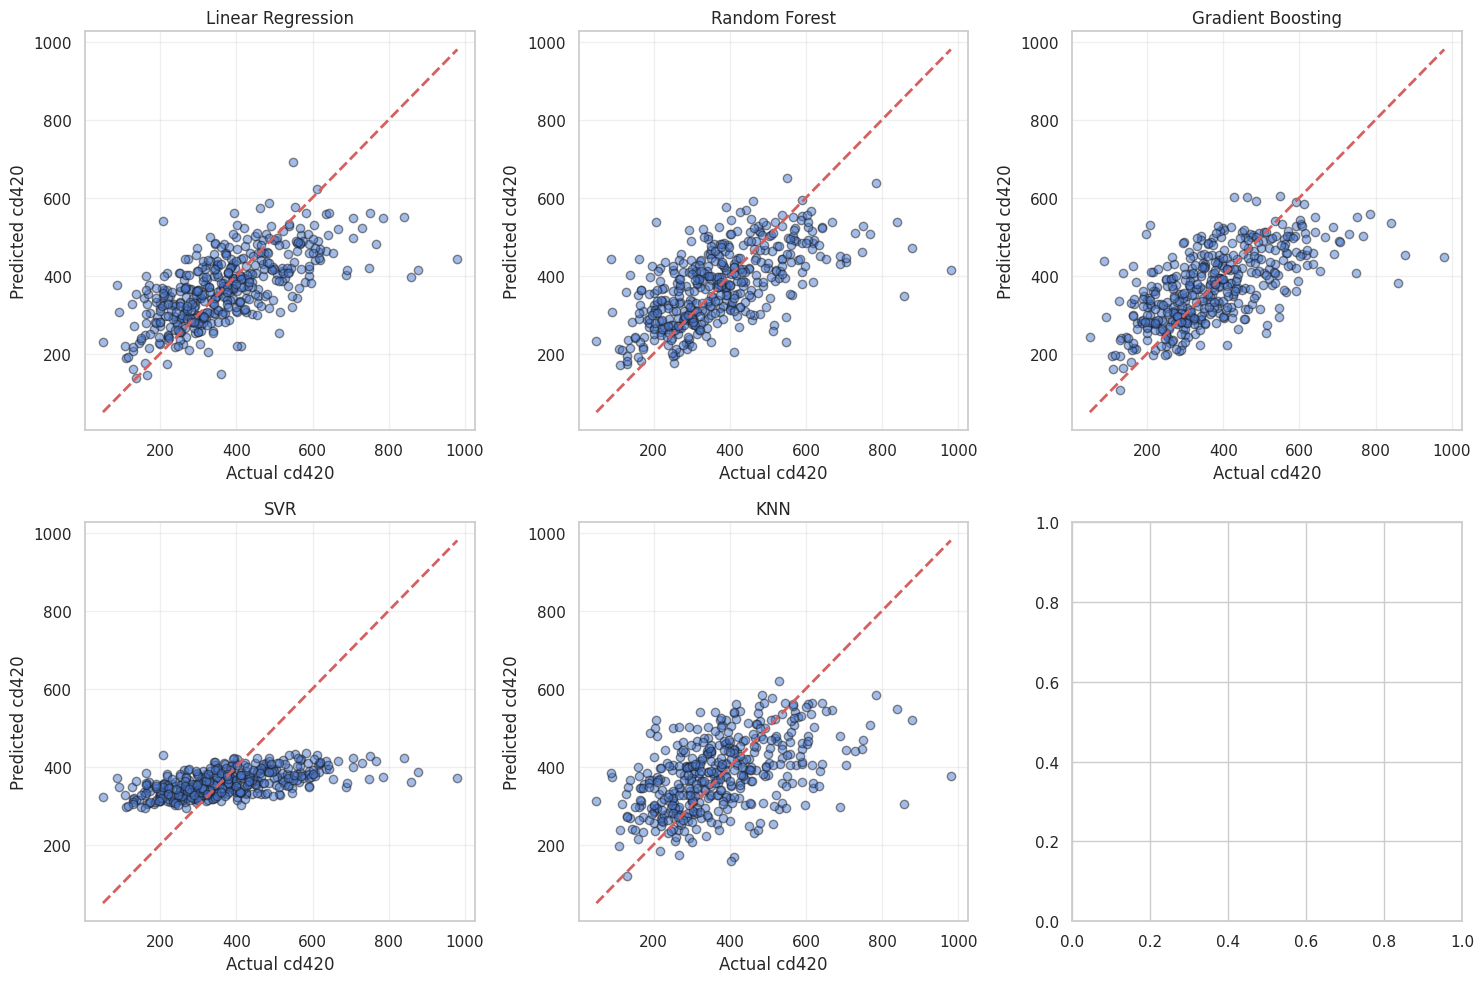

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=30),
    "Gradient Boosting": GradientBoostingRegressor(random_state=30),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor()
}

for idx, (name, model) in enumerate(models.items()):
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_test_processed)
    ax = axes[idx]
    ax.scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_xlabel('Actual cd420')
    ax.set_ylabel('Predicted cd420')
    ax.set_title(name)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

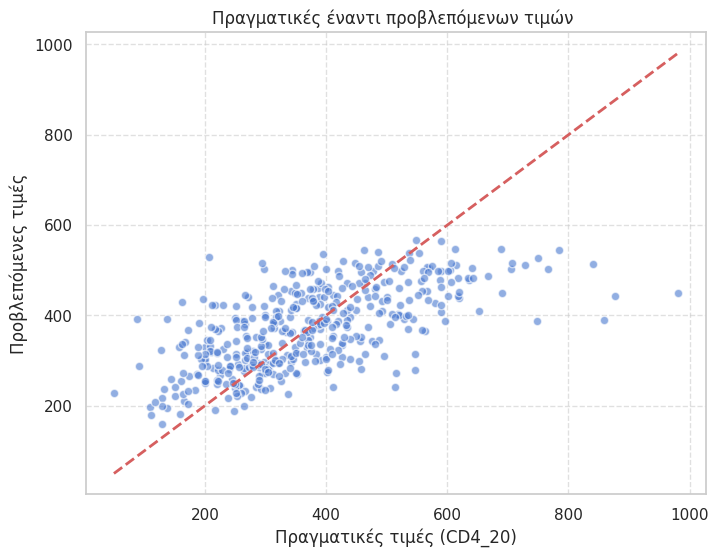

In [31]:
# 10  μεταβλητές
X_test_processed = preprocessor.transform(X_test)
X_test_selected = X_test_processed[:, rfe.support_]

# Προβλέψεις με το βέλτιστο Gradient Boosting μοντέλο
y_pred = best_gb.predict(X_test_selected)
residuals = y_test - y_pred

#  Scatter Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors='w')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Πραγματικές έναντι προβλεπόμενων τιμών ')
plt.xlabel('Πραγματικές τιμές (CD4_20)')
plt.ylabel('Προβλεπόμενες τιμές')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

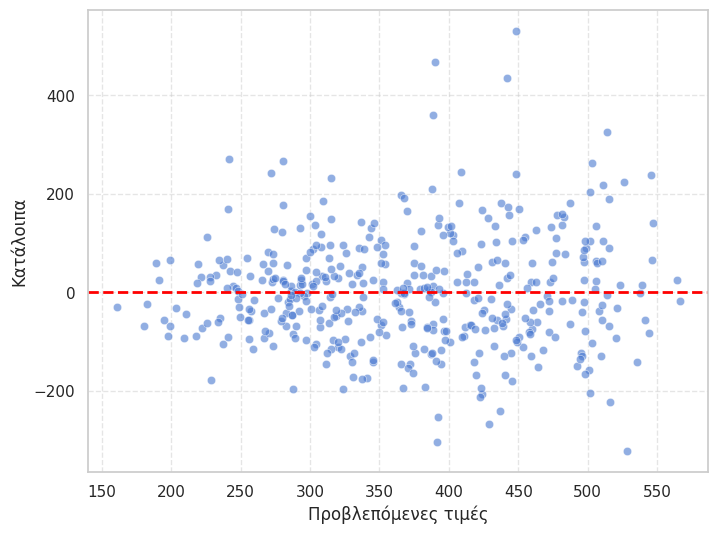

In [ ]:
# Residual Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--', lw=2)

plt.xlabel('Προβλεπόμενες τιμές')
plt.ylabel('Κατάλοιπα')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

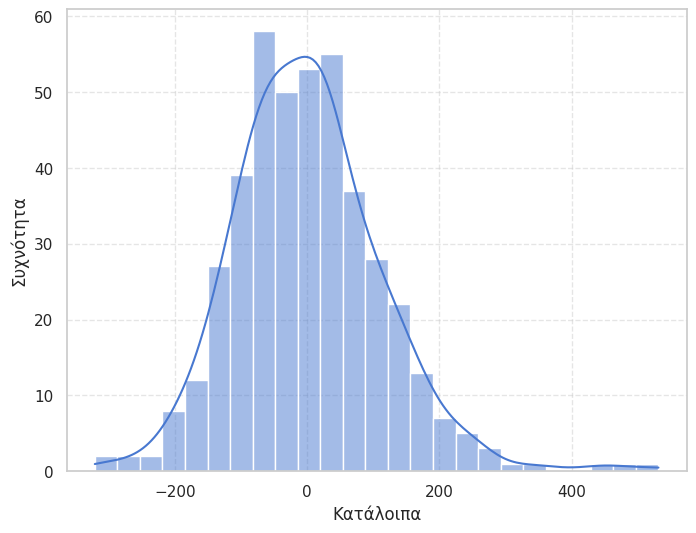

In [ ]:
#  Histogram/Density Plot
plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True)
plt.xlabel('Κατάλοιπα')
plt.ylabel('Συχνότητα')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
error_analysis = pd.DataFrame({
    'Πραγματική_Τιμή': y_test,
    'Πρόβλεψη': y_pred,
    'Απόλυτο_Σφάλμα': np.abs(residuals)
})
top_3_errors = error_analysis.sort_values(by='Απόλυτο_Σφάλμα', ascending=False).head(3)
print("Οι 3 παρατηρήσεις με το μεγαλύτερο σφάλμα:")
display(top_3_errors)

Οι 3 παρατηρήσεις με το μεγαλύτερο σφάλμα:


,Πραγματική_Τιμή,Πρόβλεψη,Απόλυτο_Σφάλμα
1781,980,448.647446,531.352554
620,858,389.911502,468.088498
650,877,441.937620,435.062380


In [ ]:
#Το πλήρες προφίλ των 3 ασθενών με το μεγαλύτερο σφάλμα
outliers_profiles = df.loc[[1781, 620, 650]]
display(outliers_profiles)

,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,str2,strat,symptom,treat,cd40,cd420,cd80
1781,1,40,93.6684,0,0,1,90,0,1,792,1,1,1,3,0,1,470,980,1510
620,1,32,80.5140,0,0,0,100,0,1,237,0,1,1,2,0,1,343,858,1059
650,2,30,97.2972,0,1,0,90,0,1,302,1,1,1,2,0,1,480,877,1320


/tmp/ipykernel_7086/2537919524.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Συντελεστής', y='Χαρακτηριστικό', data=coef_df, palette='vlag')


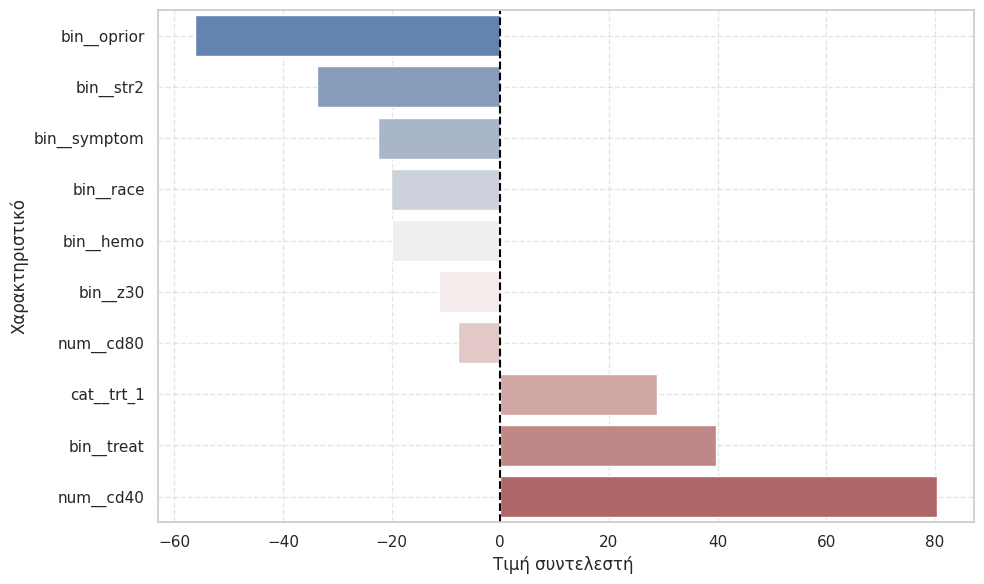

In [ ]:
#8.1

# απλό Linear Regression στα  10 features
lin_reg = LinearRegression()
lin_reg.fit(X_train_selected, y_train)
all_feature_names = preprocessor.get_feature_names_out()
# Κρατάμε μόνο τα 10 που επέλεξε το RFE
selected_features_names = all_feature_names[rfe.support_]

coef_df = pd.DataFrame({
    'Χαρακτηριστικό': selected_features_names,
    'Συντελεστής': lin_reg.coef_
})

coef_df['Απόλυτη_Τιμή'] = coef_df['Συντελεστής'].abs()
coef_df = coef_df.sort_values(by='Συντελεστής', ascending=True)

#Bar Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Συντελεστής', y='Χαρακτηριστικό', data=coef_df, palette='vlag')
plt.axvline(0, color='black', linestyle='--', linewidth=1.5)
plt.xlabel('Τιμή συντελεστή ')
plt.ylabel('Χαρακτηριστικό')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

/tmp/ipykernel_7086/2495071766.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Σημαντικότητα', y='Χαρακτηριστικό', data=importance_df, palette='mako')


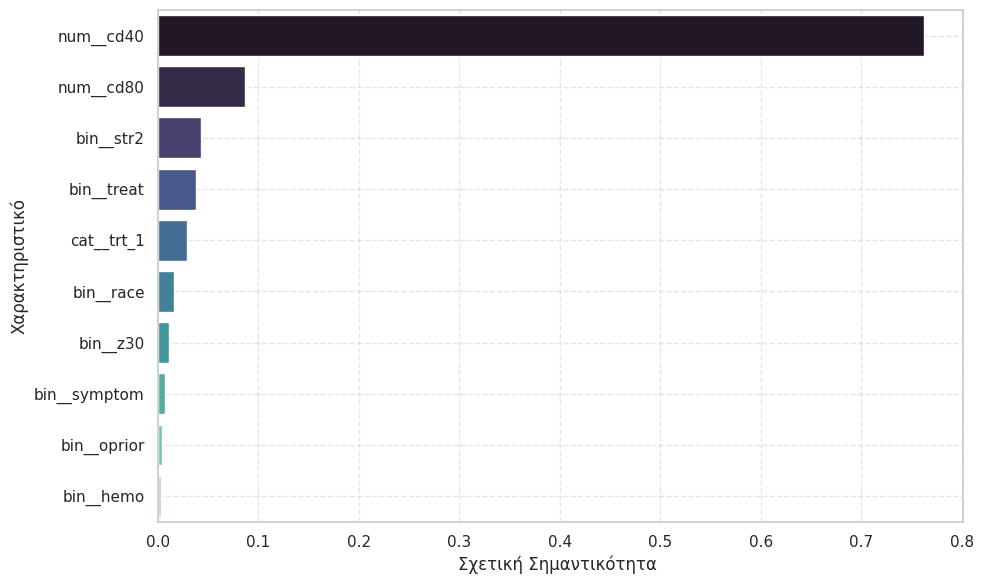

In [ ]:
#8.2 Feature Importance Gradient Boosting

feature_importances = best_gb.feature_importances_

importance_df = pd.DataFrame({
    'Χαρακτηριστικό': selected_features_names,
    'Σημαντικότητα': feature_importances
}).sort_values(by='Σημαντικότητα', ascending=False)

#Bar Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Σημαντικότητα', y='Χαρακτηριστικό', data=importance_df, palette='mako')
plt.xlabel('Σχετική Σημαντικότητα ')
plt.ylabel('Χαρακτηριστικό')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

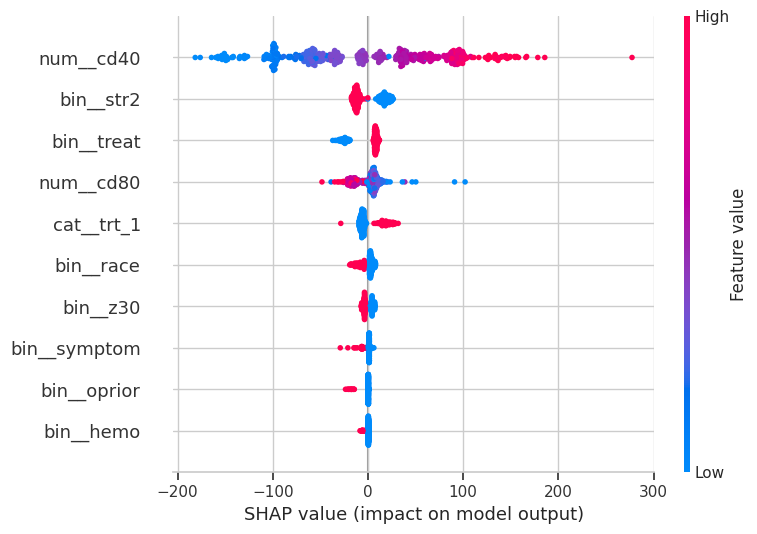

In [ ]:
#8.3 SHAP Values για τον Gradient Boosting

# Χρησιμοποιούμε το selected_features_names που βρήκαμε στο 8.1
if not isinstance(X_test_selected, pd.DataFrame):
    X_test_selected_df = pd.DataFrame(X_test_selected, columns=selected_features_names)
else:
    X_test_selected_df = X_test_selected

# SHAP TreeExplainer βελτιστοποιημένος για ensemble μοντέλα δέντρων
explainer = shap.TreeExplainer(best_gb)

shap_values = explainer.shap_values(X_test_selected_df)

#8.4 SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_selected_df, show=False)
plt.tight_layout()
plt.show()

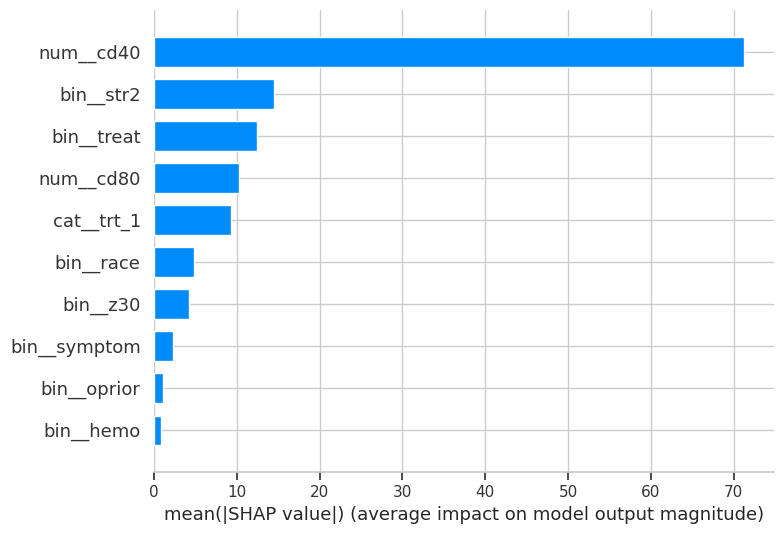

In [ ]:
#8.4 SHAP Bar Plot

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_selected_df, plot_type="bar", show=True)
plt.show()